#Basic Library

In [ ]:
#1
pip install bangla-stemmer


In [ ]:
#2
import numpy as np 
import pandas as pd
import tensorflow as tf

#Vizualize Library

In [ ]:
#3
import seaborn as sns
import matplotlib.pyplot as plt; plt.rcdefaults()
from PIL import Image

#Tensorflow Library

In [ ]:
#4
import tokenize
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Conv1D
from tensorflow.keras import regularizers
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import GlobalMaxPooling1D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from keras.preprocessing.text import Tokenizer
import tensorflow_hub as hub
from keras.layers import TimeDistributed
from tensorflow.keras.layers import Flatten
from keras.layers import BatchNormalization

#NLP library

In [ ]:
#5
import re
import nltk
nltk.download('punkt')
import string
from nltk.tokenize import word_tokenize
#nltk.download('stopwords')
#from nltk.corpus import stopwords
from bangla_stemmer.stemmer import stemmer
from sklearn.metrics import classification_report
#from sklearn.preprocessing import LabelEncoder
#from sklearn.feature_extraction.text import CountVectorizer
#from sklearn.feature_extraction.text import TfidfVectorizer

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
#6
from google.colab import drive
drive.mount('/content/drive')

Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.activity.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fexperimentsandconfigs%20https%3a%2f%2fwww.googleapis.com%2fauth%2fphotos.native&response_type=code

Enter your authorization code:
4/1AY0e-g4duUr8lfPLjvQc-9n1M_lnO_ITiQRXSVI-D7ttENIF3qtWrDoDrGE
Mounted at /content/drive


In [ ]:
#7
data_fake = pd.read_csv("/content/drive/MyDrive/Datasets/BanglaNews/MainData/Fake - Fake.csv",engine='python')
data_real = pd.read_csv("/content/drive/MyDrive/Datasets/BanglaNews/MainData/FirstFile.csv",engine='python')
data_real1 = pd.read_csv("/content/drive/MyDrive/Datasets/BanglaNews/MainData/SecondFile.csv",engine='python')

data = pd.concat([data_fake,data_real,data_real1])
#data_amazon.columns = ["Text","Label"]

In [ ]:
#8
data_fake.shape,data_real.shape,data_real1.shape

((1851, 5), (6511, 5), (1673, 5))

In [ ]:
#plt.figure(figsize=(16,9))
#sns.countplot(data.label)
#data.isna().sum()
#data.info()
#data_r = pd.concat([data_real,data_real1])
#data_r.category.value_counts().to_frame()
#data_r = pd.concat([data_real,data_real1])
#data_fake.category.value_counts().loc[lambda x : x>=2].to_frame()

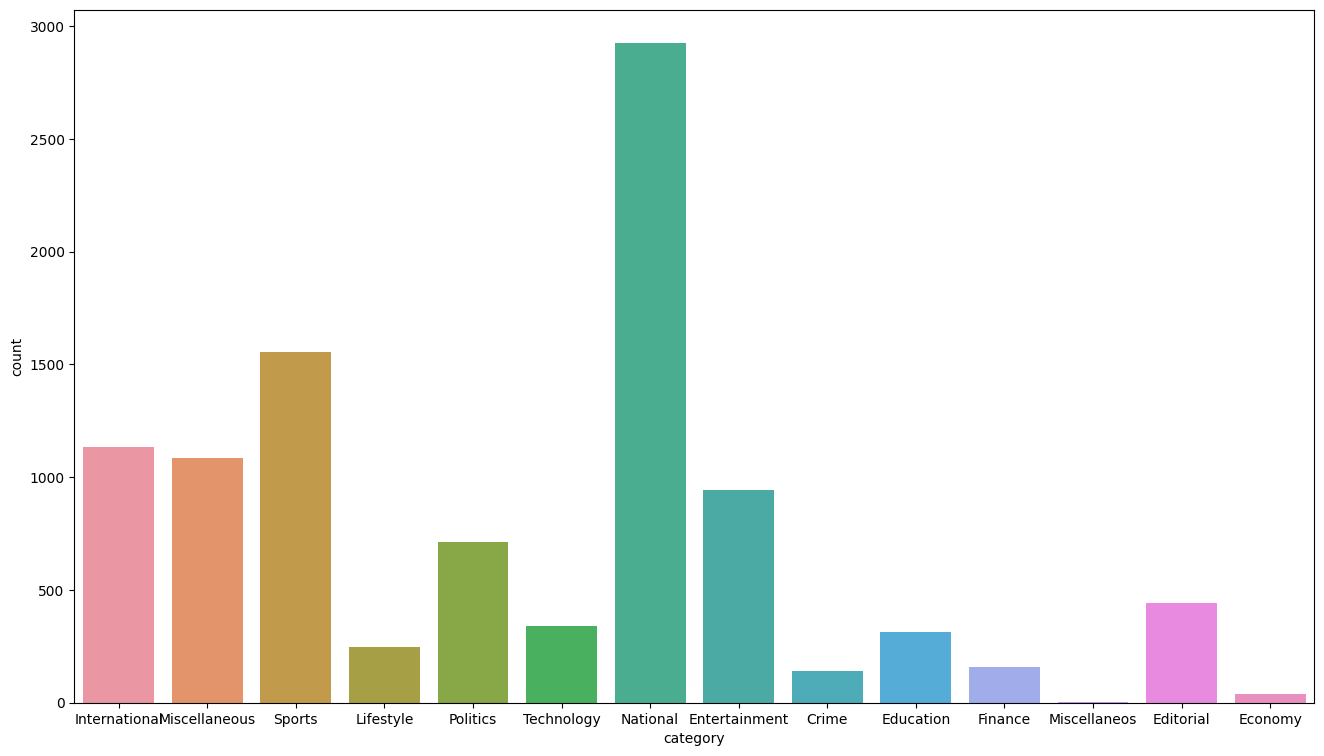

In [ ]:
plt.figure(figsize=(16,9))
sns.countplot(x='category',data=data)
#plt.figure(figsize=(16,9))
#sns.countplot(x='domain',data=data)
#plt.figure(figsize=(16,9))
#sns.countplot(x='category',hue='label',data=data)

In [ ]:
#9
data.replace('?', np.nan)

,domain,category,headline,content,label
0,channeldhaka.news,International,মুরগির হামলায় শেয়াল নিহত,"বাংলায় একটা প্রবাদ আছে, শেয়ালের কাছে মুরগী বর্...",0
1,earki.com,Miscellaneous,বিটিভিতে যেবার আমি ইন্টারভিউ দিতে গেলাম,"BTV থেকে লোকজন আসছে, ইন্টারভিউ নিবে।চারজনের টি...",0
2,earki.com,Miscellaneous,বিদেশ থেকে উন্নতমানের বিরোধীদল আমদানি করার পরা...,অদ্ভুত বিরোধীদলহীনতায় ভুগছে সরকার। এ এক অন্যরক...,0
3,channeldhaka.news,Sports,অবসর নেয়ার ঘোষণা দিলেন মেসি !,রাশিয়া বিশ্বকাপ নকআউট পর্বে ফ্রান্সের সাথে ৪-৩...,0
4,motikontho.wordpress.com,Miscellaneous,"মাদারফাকার নহে, ব্রাদারফাকার: সাকা | দৈনিক মতি...","নিজস্ব মতিবেদক‘মাদারফাকার নহে, আমি ব্রাদারফাকা...",0
...,...,...,...,...,...
1668,jagonews24.com,International,পাকিস্তানের সঙ্গে বৈঠক বাতিল করল ভারত,ভারতীয় জওয়ানদের সঙ্গে পাক রেঞ্জার্সের সদস্যদ...,1
1669,jagonews24.com,National,আদমজী ইপিজেডের পোশাক শ্রমিকদের সড়ক অবরোধ,নারায়ণগঞ্জের সিদ্ধিরগঞ্জে আদমজী ইপিজেডের রফতান...,1
1670,dailyjanakantha.com,International,"ইরানের সামরিক মহড়ায় হামলা, ৮ সেনা নিহত",ইরানের দক্ষিণপশ্চিমাঞ্চলীয় প্রদেশ খুজিস্তানে স...,1
1671,bangla.bdnews24.com,International,মধ্য প্রদেশে আশ্রয় কেন্দ্রে প্রতিবন্ধী নারীকে ...,ধর্ষণের কারণে দৃষ্টি ও বাক প্রতিবন্ধী ওই নারী ...,1


In [ ]:
#10
df = data.dropna()

In [ ]:
## Get the Independent Features
#X = df.drop('label',axis=1)

In [ ]:
#11
## Get the Dependent features
y=df['label']

In [ ]:
y.shape

(10035,)

In [ ]:
#12
t=0
cn=data["content"].values.tolist()
#c = []
for text in cn:
    pattern = re.compile('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+')
    root_word = pattern.sub('', str(text))
    text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
    root_word=nltk.word_tokenize(str(text))
    t = t + len(root_word)
    #c.append(root_word)



In [ ]:
#13
t

#Data Preprosessing



In [ ]:
#14
bangla = ["অতএব","অথচ","অথবা","অনুযায়ী","অনেক","অনেকে","অনেকেই","অন্তত","অন্য","অবধি","অবশ্য","অর্থাত","আই","আগামী","আগে","আগেই","আছে","আজ","আদ্যভাগে","আপনার","আপনি","আবার","আমরা","আমাকে","আমাদের","আমার","আমি","আর","আরও","ই","ইত্যাদি","ইহা","উচিত","উত্তর","উনি","উপর","উপরে","এ","এঁদের","এঁরা","এই","একই","একটি","একবার","একে","এক্","এখন","এখনও","এখানে","এখানেই","এটা","এটাই","এটি","এত","এতটাই","এতে","এদের","এব","এবং","এবার","এমন","এমনকী","এমনি","এর","এরা","এল","এস","এসে","ঐ","ও","ওঁদের","ওঁর","ওঁরা","ওই","ওকে","ওখানে","ওদের","ওর","ওরা","কখনও","কত","কবে","কমনে","কয়েক","কয়েকটি","করছে","করছেন","করতে","করবে","করবেন","করলে","করলেন","করা","করাই","করায়","করার","করি","করিতে","করিয়া","করিয়ে","করে","করেই","করেছিলেন","করেছে","করেছেন","করেন","কাউকে","কাছ","কাছে","কাজ","কাজে","কারও","কারণ","কি","কিংবা","কিছু","কিছুই","কিন্তু","কী","কে","কেউ","কেউই","কেখা","কেন","কোটি","কোন","কোনও","কোনো","ক্ষেত্রে","কয়েক","খুব","গিয়ে","গিয়েছে","গিয়ে","গুলি","গেছে","গেল","গেলে","গোটা","চলে","চান","চায়","চার","চালু","চেয়ে","চেষ্টা","ছাড়া","ছাড়াও","ছিল","ছিলেন","জন","জনকে","জনের","জন্য","জন্যওজে","জানতে","জানা","জানানো","জানায়","জানিয়ে","জানিয়েছে","জে","জ্নজন","টি","ঠিক","তখন","তত","তথা","তবু","তবে","তা","তাঁকে","তাঁদের","তাঁর","তাঁরা","তাঁাহারা","তাই","তাও","তাকে","তাতে","তাদের","তার","তারপর","তারা","তারৈ","তাহলে","তাহা","তাহাতে","তাহার","তিনঐ","তিনি","তিনিও","তুমি","তুলে","তেমন","তো","তোমার","থাকবে","থাকবেন","থাকা","থাকায়","থাকে","থাকেন","থেকে","থেকেই","থেকেও","দিকে","দিতে","দিন","দিয়ে","দিয়েছে","দিয়েছেন","দিলেন","দু","দুই","দুটি","দুটো","দেওয়া","দেওয়ার","দেওয়া","দেখতে","দেখা","দেখে","দেন","দেয়","দ্বারা","ধরা","ধরে","ধামার","নতুন","নয়","না","নাই","নাকি","নাগাদ","নানা","নিজে","নিজেই","নিজেদের","নিজের","নিতে","নিয়ে","নিয়ে","নেই","নেওয়া","নেওয়ার","নেওয়া","নয়","পক্ষে","পর","পরে","পরেই","পরেও","পর্যন্ত","পাওয়া","পাচ","পারি","পারে","পারেন","পি","পেয়ে","পেয়্র্","প্রতি","প্রথম","প্রভৃতি","প্রযন্ত","প্রাথমিক","প্রায়","প্রায়","ফলে","ফিরে","ফের","বক্তব্য","বদলে","বন","বরং","বলতে","বলল","বললেন","বলা","বলে","বলেছেন","বলেন","বসে","বহু","বা","বাদে","বার","বি","বিনা","বিভিন্ন","বিশেষ","বিষয়টি","বেশ","বেশি","ব্যবহার","ব্যাপারে","ভাবে","ভাবেই","মতো","মতোই","মধ্যভাগে","মধ্যে","মধ্যেই","মধ্যেও","মনে","মাত্র","মাধ্যমে","মোট","মোটেই","যখন","যত","যতটা","যথেষ্ট","যদি","যদিও","যা","যাঁর","যাঁরা","যাওয়া","যাওয়ার","যাওয়া","যাকে","যাচ্ছে","যাতে","যাদের","যান","যাবে","যায়","যার","যারা","যিনি","যে","যেখানে","যেতে","যেন","যেমন","র","রকম","রয়েছে","রাখা","রেখে","লক্ষ","শুধু","শুরু","সঙ্গে","সঙ্গেও","সব","সবার","সমস্ত","সম্প্রতি","সহ","সহিত","সাধারণ","সামনে","সি","সুতরাং","সে","সেই","সেখান","সেখানে","সেটা","সেটাই","সেটাও","সেটি","স্পষ্ট","স্বয়ং","হইতে","হইবে","হইয়া","হওয়া","হওয়ায়","হওয়ার","হচ্ছে","হত","হতে","হতেই","হন","হবে","হবেন","হয়","হয়তো","হয়নি","হয়ে","হয়েই","হয়েছিল","হয়েছে","হয়েছেন","হল","হলে","হলেই","হলেও","হলো","হাজার","হিসাবে","হৈলে","হোক","হয়"]

In [ ]:
raw = "গত ১৭ সেপ্টেম্বর বাংলাদেশ কৃষি বিশ্ববিদ্যালয়ে (বাকৃবি) উপাচার্যের কার্যালয়ে হট্টগোলের ঘটনায় দুইজনকে সাময়িক বরখাস্ত ও ছয় জনকে শোকজ করেছে বিশ্ববিদ্যালয় প্রশাসন।"

In [ ]:
pattern = re.compile('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+')
root_word = pattern.sub('', str(raw))
text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
root_word=nltk.word_tokenize(str(text))
tokens_without_sw = [k for k in root_word if not k in bangla]
stmr = stemmer.BanglaStemmer()
words = [stmr.stem(w) for w in root_word if not w in tokens_without_sw]
#text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
print(words)

applied second rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied second rules..
['গত', '১৭', 'সেপ্টেম্বর', 'বাংলাদেশ', 'কৃষি', 'বিশ্ববিদ্যালয়', 'বাকৃবি', 'উপাচার্যের', 'কার্যালয়', 'হট্টগোল', 'ঘটনায়', 'দুইজনকে', 'সাময়িক', 'বরখাস্ত', 'ছয়', 'শোকজ', 'বিশ্ববিদ্যালয়', 'প্রশাসন']


In [ ]:
#15
cn=data["content"].values.tolist()
corpus = []
for text in cn:
    pattern = re.compile('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+')
    root_word = pattern.sub('', str(text))
    text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
    root_word=nltk.word_tokenize(str(text))
    tokens_without_sw = [k for k in root_word if not k in bangla]
    stmr = stemmer.BanglaStemmer()
    words = [stmr.stem(w) for w in root_word if not w in tokens_without_sw]
    words = ' '.join(words)
    #print(words)
    corpus.append(words)

#Onehot Representation

In [ ]:
#onehot_repr
#voc_size = 10000
#onehot_repr=[one_hot(words,voc_size)for words in corpus] 

#Padding

In [ ]:
#sent_length=500
#embedded_docs=pad_sequences(onehot_repr,padding='pre',maxlen=sent_length)
#print(embedded_docs)

In [ ]:
#embedded_docs[0]
#len(embedded_docs),y.shape

#Word2vec Model

In [ ]:
#16
cn1=data["content"].values.tolist()
corpus1 = []
for text in cn1:
    pattern = re.compile('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+')
    root_word = pattern.sub('', str(text))
    text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
    root_word=nltk.word_tokenize(str(text))
    #words = ' '.join(root_word)
    corpus1.append(root_word)

In [ ]:
#17
cn4=data["content"].values.tolist()
corpus4 = []
for text in cn4:
    pattern = re.compile('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+')
    root_word = pattern.sub('', str(text))
    text = re.sub(r"[,.।‘’\"!@#$%^&*(){}?/;`~:<>+=-]", "", root_word)
    root_word=nltk.word_tokenize(str(text))
    tokens_without_sw = [k for k in root_word if not k in bangla]
    stmr = stemmer.BanglaStemmer()
    words = [stmr.stem(w) for w in root_word if not w in tokens_without_sw]
    corpus4.append(words)

In [ ]:
#18
import gensim
Embedding_Dim = 100
word2v = gensim.models.Word2Vec(corpus1+corpus4, size= Embedding_Dim, window =10, min_count=1)

In [ ]:
#19
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)

corpus = tokenizer.texts_to_sequences(corpus)

In [ ]:
#20
len(word2v.wv.vocab)

134113

In [ ]:
#21
vector = word2v.wv['ঘোষণা']
vector

array([-0.9351477 , -0.18719012,  4.217818  ,  5.168444  , -5.6596684 ,
       -2.3253086 , -1.4575789 ,  1.4232608 ,  1.7797077 , -0.1299411 ,
        3.712308  ,  1.6070457 , -1.6291257 ,  0.1159448 ,  0.4815097 ,
        2.3428307 ,  0.63338584, -0.5254039 , -3.879654  ,  1.4101086 ,
        2.4624252 , -4.788408  , -0.99386877, -2.1517134 ,  1.0066766 ,
        0.8654898 , -1.3025539 , -0.02068626, -0.03524725, -1.9692963 ,
       -0.9536822 ,  0.7146425 , -1.5232463 , -1.6979895 ,  2.0749073 ,
       -0.23199154,  5.9405913 ,  1.5577824 , -0.41533443,  1.5951469 ,
       -0.66621715, -0.47415084, -0.44455278, -0.3084143 ,  2.0136156 ,
        0.41836086,  3.3265765 ,  1.5922513 ,  1.4494385 , -1.0945433 ,
        2.898357  , -0.18080133, -0.9441522 , -1.1883914 , -1.261466  ,
        1.4285334 , -0.51892996, -3.349558  , -1.2490327 , -1.98882   ,
        2.064221  ,  0.80415785, -0.36461776,  0.1940213 ,  1.4855378 ,
       -3.2828555 , -4.1515055 , -1.2130225 ,  1.8603971 ,  1.93

In [ ]:
#22
similar = word2v.wv.most_similar('সামরিক')
similar

[('সেনাবাহিনীর', 0.8827696442604065),
 ('রাশিয়ার', 0.8705707788467407),
 ('রুশ', 0.8586262464523315),
 ('দেশটির', 0.8487431406974792),
 ('গণহত্যা', 0.8477731943130493),
 ('সিরিয়ার', 0.8385252952575684),
 ('ক্ষেপণাস্ত্র', 0.832740843296051),
 ('রাখাইনে', 0.8308510184288025),
 ('ইসরাইলের', 0.829788088798523),
 ('সিরিয়ায়', 0.8183717727661133)]

In [ ]:
#23
word_index = tokenizer.word_index
for word, num in word_index.items():
    print(f"{word} -> {num}")
    if num == 5:
        break 

কর -> 1
ও -> 2
করে -> 3
না -> 4
থেক -> 5


In [ ]:
#24
sent_length=500
embedded_docs1=pad_sequences(corpus,padding='pre',maxlen=sent_length)
embedded_docs1[0]

In [ ]:
#25
vocab_size = len(tokenizer.word_index) + 1

In [ ]:
#26
vocab_size

In [ ]:
#27
def get_weight_matrix(model, vocab):
    # total vocabulary size plus 1 for unknown words
    vocab_size = len(vocab) + 1
    # define weight matrix dimensions with all 0
    weight_matrix = np.zeros((vocab_size, Embedding_Dim))
    # step vocab, store vectors using the Tokenizer's integer mapping
    for word, i in vocab.items():
        weight_matrix[i] = model[word]
    return weight_matrix

In [ ]:
#28
embedding_vectors = get_weight_matrix(word2v, word_index)
embedding_vectors

#LSTM Model

In [ ]:
#29
sent_length=500
#embedding_vector_features=60
model=Sequential()
#model.add(Embedding(voc_size,embedding_vector_features,input_length=sent_length))
model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length,trainable=False))
model.add(LSTM(150))
model.add(Dropout(0.5))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

Model: "sequential_13"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_13 (Embedding)     (None, 500, 100)          32100     
_________________________________________________________________
lstm_7 (LSTM)                (None, 150)               150600    
_________________________________________________________________
dropout_13 (Dropout)         (None, 150)               0         
_________________________________________________________________
dense_13 (Dense)             (None, 1)                 151       
Total params: 182,851
Trainable params: 150,751
Non-trainable params: 32,100
_________________________________________________________________
None


#Testing&Training

In [ ]:
#X_final=np.asarray(embedded_docs).astype(np.float32)
#y_final=np.asarray(y)
#X_final.shape,y_final.shape

In [ ]:
#30
from sklearn.model_selection import train_test_split
X1_train, X1_test, y1_train, y1_test = train_test_split(embedded_docs1, y, test_size=0.2, random_state=42)

In [ ]:
#31
history = model.fit(X1_train,y1_train,validation_data=(X1_test,y1_test),epochs=10,batch_size=64)

Epoch 1/10
126/126 [==============================] - 168s 1s/step - loss: 0.3978 - accuracy: 0.8301 - val_loss: 0.2925 - val_accuracy: 0.8829
Epoch 2/10
126/126 [==============================] - 166s 1s/step - loss: 0.2756 - accuracy: 0.8872 - val_loss: 0.2788 - val_accuracy: 0.8939
Epoch 3/10
126/126 [==============================] - 167s 1s/step - loss: 0.2574 - accuracy: 0.8979 - val_loss: 0.2326 - val_accuracy: 0.9098
Epoch 4/10
126/126 [==============================] - 164s 1s/step - loss: 0.2277 - accuracy: 0.9130 - val_loss: 0.2339 - val_accuracy: 0.9148
Epoch 5/10
126/126 [==============================] - 163s 1s/step - loss: 0.1890 - accuracy: 0.9281 - val_loss: 0.2277 - val_accuracy: 0.9158
Epoch 6/10
126/126 [==============================] - 162s 1s/step - loss: 0.1725 - accuracy: 0.9397 - val_loss: 0.2176 - val_accuracy: 0.9173
Epoch 7/10
126/126 [==============================] - 161s 1s/step - loss: 0.1588 - accuracy: 0.9407 - val_loss: 0.2130 - val_accuracy: 0.9253

In [ ]:
#32
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#33
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#34
y_pred=model.predict_classes(X1_test)

/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '


#Confusion Matrix

In [ ]:
#35
print(classification_report(y1_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.68      0.77       387
           1       0.93      0.98      0.95      1620

    accuracy                           0.92      2007
   macro avg       0.91      0.83      0.86      2007
weighted avg       0.92      0.92      0.92      2007



#CNN Model

In [ ]:
#36
sent_length=500
model=Sequential()
model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length, trainable=False))

model.add(Conv1D(128,4,activation='relu',kernel_regularizer = regularizers.l2(0.0005),bias_regularizer = regularizers.l2(0.0005)))                               
model.add(GlobalMaxPooling1D())
model.add(Dropout(0.5))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (None, 500, 100)          32100     
_________________________________________________________________
conv1d (Conv1D)              (None, 497, 128)          51328     
_________________________________________________________________
global_max_pooling1d (Global (None, 128)               0         
_________________________________________________________________
dropout (Dropout)            (None, 128)               0         
_________________________________________________________________
dense (Dense)                (None, 1)                 129       
Total params: 83,557
Trainable params: 51,457
Non-trainable params: 32,100
_________________________________________________________________
None


In [ ]:
#37
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(embedded_docs1, y, test_size=0.2, random_state=42)

In [ ]:
#38
history1 = model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=10,batch_size=64)

Epoch 1/10
126/126 [==============================] - 26s 196ms/step - loss: 0.9125 - accuracy: 0.7748 - val_loss: 0.3302 - val_accuracy: 0.8919
Epoch 2/10
126/126 [==============================] - 24s 189ms/step - loss: 0.3586 - accuracy: 0.8856 - val_loss: 0.3130 - val_accuracy: 0.8929
Epoch 3/10
126/126 [==============================] - 24s 190ms/step - loss: 0.3081 - accuracy: 0.8990 - val_loss: 0.2933 - val_accuracy: 0.9038
Epoch 4/10
126/126 [==============================] - 24s 187ms/step - loss: 0.2824 - accuracy: 0.9130 - val_loss: 0.3199 - val_accuracy: 0.8899
Epoch 5/10
126/126 [==============================] - 24s 191ms/step - loss: 0.2532 - accuracy: 0.9270 - val_loss: 0.3242 - val_accuracy: 0.8884
Epoch 6/10
126/126 [==============================] - 24s 190ms/step - loss: 0.2490 - accuracy: 0.9281 - val_loss: 0.2804 - val_accuracy: 0.9138
Epoch 7/10
126/126 [==============================] - 24s 194ms/step - loss: 0.2293 - accuracy: 0.9343 - val_loss: 0.2885 - val_ac

In [ ]:
#39
plt.plot(history1.history['accuracy'])
plt.plot(history1.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#40
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

#Confusion Matrix

In [ ]:
#41
y1_pred=model.predict_classes(X_test)

/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '


In [ ]:
#42
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y1_pred)
from sklearn.metrics import accuracy_score,f1_score, precision_score
#accuracy_score(y_test,y_pred)
print(classification_report(y_test, y1_pred))

              precision    recall  f1-score   support

           0       0.91      0.56      0.69       387
           1       0.90      0.99      0.94      1620

    accuracy                           0.90      2007
   macro avg       0.91      0.77      0.82      2007
weighted avg       0.90      0.90      0.89      2007



#CNN-LSTM Architecture

In [ ]:
#43
embedding_vector_features=60
model=Sequential()
model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length, trainable = False))
#model.add(Embedding(voc_size,embedding_vector_features,input_length=sent_length))
model.add(Conv1D(128,4,padding='same', activation='relu',kernel_regularizer = regularizers.l2(0.0005),bias_regularizer = regularizers.l2(0.0005)))
model.add(BatchNormalization())
model.add(MaxPooling1D())
model.add(LSTM(150))
model.add(Dropout(0.5))  
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_2 (Embedding)      (None, 500, 100)          32100     
_________________________________________________________________
conv1d_2 (Conv1D)            (None, 500, 128)          51328     
_________________________________________________________________
batch_normalization_1 (Batch (None, 500, 128)          512       
_________________________________________________________________
max_pooling1d_1 (MaxPooling1 (None, 250, 128)          0         
_________________________________________________________________
lstm_1 (LSTM)                (None, 150)               167400    
_________________________________________________________________
dropout_2 (Dropout)          (None, 150)               0         
_________________________________________________________________
dense_2 (Dense)              (None, 1)                

In [ ]:
#44
from sklearn.model_selection import train_test_split
X2_train, X2_test, y2_train, y2_test = train_test_split(embedded_docs1, y, test_size=0.2, random_state=42)

In [ ]:
#45
history2 = model.fit(X2_train,y2_train,validation_data=(X2_test,y2_test),epochs=10,batch_size=64)

Epoch 1/10
126/126 [==============================] - 129s 1s/step - loss: 0.4651 - accuracy: 0.8245 - val_loss: 0.3569 - val_accuracy: 0.8635
Epoch 2/10
126/126 [==============================] - 126s 1s/step - loss: 0.3146 - accuracy: 0.8939 - val_loss: 0.3474 - val_accuracy: 0.8849
Epoch 3/10
126/126 [==============================] - 128s 1s/step - loss: 0.2742 - accuracy: 0.9199 - val_loss: 0.2963 - val_accuracy: 0.9093
Epoch 4/10
126/126 [==============================] - 128s 1s/step - loss: 0.2427 - accuracy: 0.9327 - val_loss: 0.3196 - val_accuracy: 0.9068
Epoch 5/10
126/126 [==============================] - 129s 1s/step - loss: 0.2050 - accuracy: 0.9426 - val_loss: 0.3371 - val_accuracy: 0.8874
Epoch 6/10
126/126 [==============================] - 129s 1s/step - loss: 0.1701 - accuracy: 0.9606 - val_loss: 0.3736 - val_accuracy: 0.9023
Epoch 7/10
126/126 [==============================] - 129s 1s/step - loss: 0.1512 - accuracy: 0.9639 - val_loss: 0.3700 - val_accuracy: 0.8809

In [ ]:
#46
plt.plot(history2.history['accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#47
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#48
y2_pred=model.predict_classes(X2_test)

/usr/local/lib/python3.7/dist-packages/tensorflow/python/keras/engine/sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '


In [ ]:
#49
from sklearn.metrics import confusion_matrix
confusion_matrix(y2_test,y2_pred)
from sklearn.metrics import accuracy_score,f1_score, precision_score
print(classification_report(y2_test, y2_pred))

              precision    recall  f1-score   support

           0       0.89      0.67      0.76       387
           1       0.93      0.98      0.95      1620

    accuracy                           0.92      2007
   macro avg       0.91      0.82      0.86      2007
weighted avg       0.92      0.92      0.92      2007



#Cross Validation

#CNN

In [ ]:
#50
from sklearn.model_selection import train_test_split,KFold,cross_val_score
kfold=KFold(5,True,7)
cvscores = []
for train, test in kfold.split(embedded_docs1,y):

    X3_train, X3_test, y3_train, y3_test = train_test_split(embedded_docs1, y, test_size = 0.2, random_state = 42)

    model=Sequential()
    model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length, trainable=False))
    model.add(Conv1D(128,4, activation='relu',kernel_regularizer = regularizers.l2(0.0005),bias_regularizer = regularizers.l2(0.0005)))                               
    model.add(GlobalMaxPooling1D())
    model.add(Dropout(0.5))
    model.add(Dense(1,activation='sigmoid'))
    model.compile(loss='binary_crossentropy',optimizer='adam',metrics=["accuracy"])

    model.fit(X3_train, y3_train, epochs=10, batch_size=10, verbose=0,shuffle=False)
    scores = model.evaluate(X3_test, y3_test, verbose=0)
    print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))
    cvscores.append(scores[1] * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))

accuracy: 90.73%
accuracy: 91.03%
accuracy: 90.78%
accuracy: 89.84%
accuracy: 91.38%
90.75% (+/- 0.51%)


#CNN-LSTM

In [ ]:
#51
from sklearn.model_selection import train_test_split,KFold,cross_val_score
kfold=KFold(5,True,7)
cvscores = []
for train, test in kfold.split(embedded_docs1,y):

    X4_train, X4_test, y4_train, y4_test = train_test_split(embedded_docs1, y, test_size = 0.2, random_state = 42)

    model=Sequential()
    model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length, trainable = False))
    model.add(Conv1D(128,4,padding='same', activation='relu',kernel_regularizer = regularizers.l2(0.0005),bias_regularizer = regularizers.l2(0.0005)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D())  
    model.add(LSTM(150))                            
    model.add(Dropout(0.5))
    model.add(Dense(1,activation='sigmoid'))
    model.compile(loss='binary_crossentropy',optimizer='adam',metrics=["accuracy"])

    model.fit(X4_train, y4_train, epochs=10, batch_size=10, verbose=0,shuffle=False)
    scores = model.evaluate(X4_test, y4_test, verbose=0)
    print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))
    cvscores.append(scores[1] * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))

accuracy: 90.73%
accuracy: 90.03%
accuracy: 89.64%
accuracy: 90.38%
accuracy: 90.33%
90.22% (+/- 0.37%)


#LSTM

In [ ]:
#52
from sklearn.model_selection import train_test_split,KFold,cross_val_score
kfold=KFold(5,True,7)
cvscores = []
for train, test in kfold.split(embedded_docs1,y):

    X5_train, X5_test, y5_train, y5_test = train_test_split(embedded_docs1, y, test_size = 0.2, random_state = 42)

    model=Sequential()
    model.add(Embedding(vocab_size, output_dim=Embedding_Dim, weights=[embedding_vectors], input_length=sent_length, trainable=False))
    model.add(LSTM(150))
    model.add(Dropout(0.5))
    model.add(Dense(1,activation='sigmoid'))
    model.compile(loss='binary_crossentropy',optimizer='adam',metrics=["accuracy"])

    model.fit(X5_train, y5_train, epochs=10, batch_size=10, verbose=0,shuffle=False)
    scores = model.evaluate(X5_test, y5_test, verbose=0)
    print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))
    cvscores.append(scores[1] * 100)
print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))

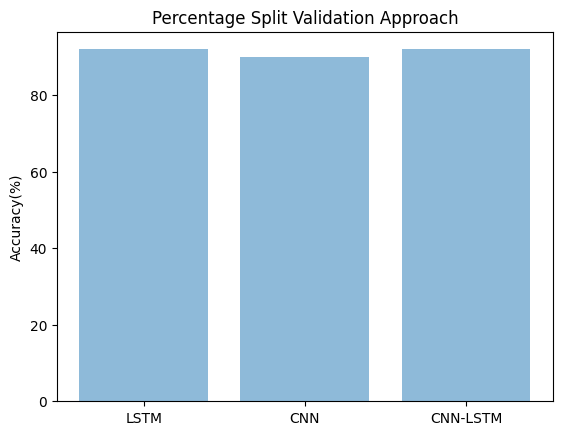

In [ ]:
#53
objects = ('LSTM', 'CNN', 'CNN-LSTM')
y_pos = np.arange(len(objects))
performance = [92,90,92]

plt.bar(y_pos, performance, align='center', alpha=0.5)
plt.xticks(y_pos, objects)
plt.ylabel('Accuracy(%)')
plt.title('Percentage Split Validation Approach')

plt.show()

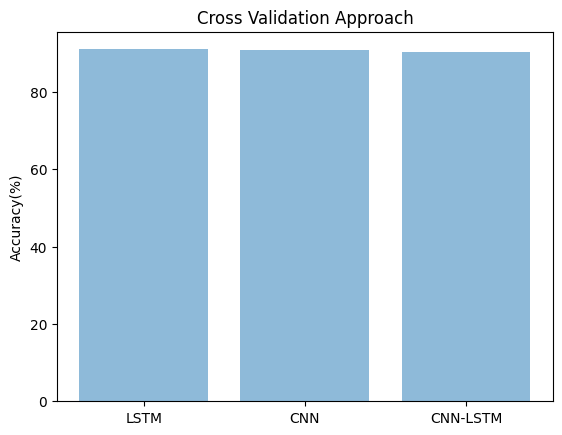

In [ ]:
#54
objects = ('LSTM', 'CNN', 'CNN-LSTM')
y_pos = np.arange(len(objects))
performance = [91.03,90.75,90.22]

plt.bar(y_pos, performance, align='center', alpha=0.5)
plt.xticks(y_pos, objects)
plt.ylabel('Accuracy(%)')
plt.title('Cross Validation Approach')

plt.show()